In [1]:
import pandas as pd 
import numpy as np

In [2]:
df=pd.read_csv("Weather_classification_data.csv")

In [3]:
df

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,18.0,58,10.0,28.0,partly cloudy,1017.27,4.0,Summer,8.0,coastal,Cloudy
1,32.0,57,10.0,46.0,overcast,1011.05,3.0,Autumn,5.5,inland,Cloudy
2,21.0,73,11.5,85.0,overcast,1006.09,2.0,Spring,5.5,inland,Rainy
3,11.0,77,13.0,21.0,partly cloudy,1003.85,4.0,Spring,5.0,coastal,Cloudy
4,28.0,84,37.5,105.0,partly cloudy,1018.64,5.0,Spring,2.0,inland,Rainy
...,...,...,...,...,...,...,...,...,...,...,...
8495,32.0,39,7.5,3.0,clear,1021.43,9.0,Autumn,5.5,inland,Sunny
8496,42.0,33,5.5,19.0,partly cloudy,1028.78,8.0,Spring,6.5,inland,Sunny
8497,19.0,63,15.0,15.0,overcast,1012.77,2.0,Winter,7.5,coastal,Cloudy
8498,29.0,69,10.5,44.0,overcast,1001.44,2.0,Winter,8.0,inland,Cloudy


In [4]:
# check the duplicates and missing values 
print(df.duplicated().sum())
print(df.isnull().sum())

334
Temperature              0
Humidity                 0
Wind Speed               0
Precipitation (%)        0
Cloud Cover             85
Atmospheric Pressure     0
UV Index                84
Season                   0
Visibility (km)          0
Location                 0
Weather Type             0
dtype: int64


In [5]:
df=df.drop_duplicates()
df = df.ffill()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8166 entries, 0 to 8165
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           8166 non-null   float64
 1   Humidity              8166 non-null   int64  
 2   Wind Speed            8166 non-null   float64
 3   Precipitation (%)     8166 non-null   float64
 4   Cloud Cover           8166 non-null   object 
 5   Atmospheric Pressure  8166 non-null   float64
 6   UV Index              8166 non-null   float64
 7   Season                8166 non-null   object 
 8   Visibility (km)       8166 non-null   float64
 9   Location              8166 non-null   object 
 10  Weather Type          8166 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 765.6+ KB


In [7]:
# define the numerical and categorical features
numCols = ['Temperature', 'Humidity', 'Wind Speed','Precipitation (%)','Atmospheric Pressure','UV Index','Visibility (km)']
categCols = ['Cloud Cover', 'Season', 'Location']

In [8]:
#Calculate the first quartile (Q1) and third quartile (Q3) for each numerical column
Q1 = df[numCols].quantile(0.25)
Q3 = df[numCols].quantile(0.75)
IQR = Q3 - Q1
# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
# Filter the data
mask = ~((df[numCols] < lower_bound) | (df[numCols] > upper_bound)).any(axis=1)
# Drop all rows identified as outliers based on the mask
df.drop(index=df.index[~mask], inplace=True)

In [9]:
# Check if the data imbalanced 
print(df['Weather Type'].value_counts())

Weather Type
Sunny     2514
Cloudy    2310
Rainy     1953
Snowy      261
Name: count, dtype: int64


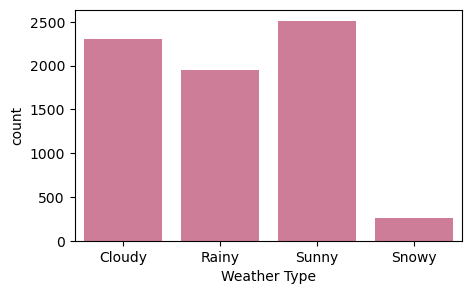

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5, 3)) 
sns.countplot(x = df['Weather Type'] , color="palevioletred")
plt.show()

In [11]:
# split the feature and the target :
Features1= df.drop(['Weather Type'], axis=1)  
Target1 = df['Weather Type']      

In [12]:
# seperate the sample to train and test 
from sklearn.model_selection import train_test_split
Xtrain, Xtest, Ytrain, Ytest = train_test_split(Features1, Target1, test_size=0.25, random_state=43)

In [13]:
# Check the number of unique value befor encoding :
for col in categCols:
    print(col, df[col].nunique())

Cloud Cover 4
Season 4
Location 3


In [14]:
# Normalaization and encode 
from sklearn.preprocessing import MinMaxScaler

#One-hot encode categorical features
Xtrain = pd.get_dummies(Xtrain, columns=categCols, drop_first=True, dtype=int)
Xtest = pd.get_dummies(Xtest, columns=categCols, drop_first=True, dtype=int)

#Scale numeric features
scaler = MinMaxScaler()
Xtrain[numCols] = scaler.fit_transform(Xtrain[numCols])
Xtest[numCols] = scaler.transform(Xtest[numCols])

from sklearn.preprocessing import LabelEncoder

# Encode target classes ('Sunny','Rainy','Cloudy','Snowy') into numbers
label_encoder = LabelEncoder()
Ytrain_encoded = label_encoder.fit_transform(Ytrain)
Ytest_encoded = label_encoder.transform(Ytest)


In [15]:
# Balance the data
from imblearn.over_sampling import BorderlineSMOTE
smote = BorderlineSMOTE(random_state=43)
Xtrain_resampled, Ytrain_resampled = smote.fit_resample(Xtrain, Ytrain_encoded)

C:\Users\olada\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [16]:
# see the data after balancing : 

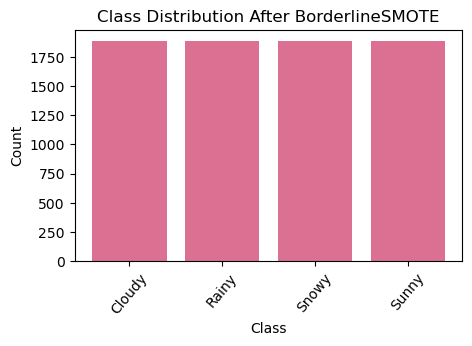

In [17]:
import matplotlib.pyplot as plt

unique, counts = np.unique(Ytrain_resampled, return_counts=True)
labels = label_encoder.inverse_transform(unique)

plt.figure(figsize=(5,3))
plt.bar(labels, counts, color='palevioletred')
plt.title("Class Distribution After BorderlineSMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=50)
plt.show()


In [18]:
Xtrain_resampled

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km),Cloud Cover_cloudy,Cloud Cover_overcast,Cloud Cover_partly cloudy,Season_Spring,Season_Summer,Season_Winter,Location_inland,Location_mountain
0,0.656250,0.123596,0.098039,0.036697,0.698535,0.357143,0.517241,0,0,0,1,0,0,1,0
1,0.453125,0.584270,0.274510,0.431193,0.489278,0.214286,0.413793,0,1,0,0,0,1,0,1
2,0.828125,0.808989,0.215686,0.853211,0.558256,1.000000,0.344828,0,0,1,0,0,1,0,0
3,0.546875,0.157303,0.196078,0.055046,0.811115,0.714286,0.551724,0,0,1,0,0,0,0,0
4,0.750000,0.089888,0.196078,0.045872,0.609185,0.500000,0.655172,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7543,0.140625,0.945726,0.420137,0.713451,0.112814,0.903089,0.126235,0,0,1,0,0,1,1,0
7544,0.161964,0.767350,0.091821,0.867759,0.093059,0.297956,0.210247,0,0,1,0,0,1,0,1
7545,0.062803,0.550998,0.375941,0.686138,0.279594,0.071429,0.322945,0,0,1,0,0,1,0,1
7546,0.171875,0.634173,0.403186,0.837586,0.181505,0.051060,0.344828,0,0,1,0,0,1,0,1


In [19]:
###Feature selection : 

In [20]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE,chi2 
from sklearn.linear_model import LogisticRegression
import pandas as pd
# Use f_classif since the most important features like temperature are numerical and continuous
# f_classif evaluates the correlation between each feature and the target
Kselector = SelectKBest(score_func=f_classif, k=13)
X_kbest = Kselector.fit_transform(Xtrain_resampled, Ytrain_resampled)
# Boolean mask of selected features
kbestFeatures = Kselector.get_support()
# Get the selected feature names
selected_features_kbest = Xtrain_resampled.columns[kbestFeatures]
print("Top 13 features from SelectKBest:" ,list(selected_features_kbest) )
# 2. RFE using LogisticRegression as the estimator
LRselector = LogisticRegression(max_iter=700) 
# Apply RFE to reduce features to top 11
RFEselector = RFE(estimator=LRselector, n_features_to_select=11)
# Fit on features selected by SelectKBest
selected_features_kbestDF = Xtrain_resampled[selected_features_kbest]
X_rfe = RFEselector.fit_transform(selected_features_kbestDF, Ytrain_resampled)
# Boolean mask from RFE
mask_rfe = RFEselector.get_support()
# Final selected features after RFE
final_selected_features = selected_features_kbest[mask_rfe]
print("\nFinal top 11 features after RFE:\n" , list(final_selected_features))


Top 13 features from SelectKBest: ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)', 'Cloud Cover_overcast', 'Cloud Cover_partly cloudy', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'Location_mountain']

Final top 11 features after RFE:
 ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)', 'Cloud Cover_overcast', 'Cloud Cover_partly cloudy', 'Season_Winter', 'Location_mountain']


In [21]:
###Train and Evaluat machine learning algorithms

In [22]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [23]:
from sklearn.neural_network import MLPClassifier

MLP_model = MLPClassifier(solver="sgd" , alpha=1e-5 , hidden_layer_sizes=(64,32) ,max_iter=2000, random_state=43)

MLP_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
MLP_pred = MLP_model.predict(Xtest[final_selected_features])
print("\nMLP test accuracy:", accuracy_score(Ytest_encoded, MLP_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, MLP_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Ytest_encoded, MLP_pred))


MLP test accuracy: 0.9630681818181818

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.95      0.95       571
           1       0.95      0.98      0.96       501
           2       0.98      0.97      0.98        61
           3       0.98      0.96      0.97       627

    accuracy                           0.96      1760
   macro avg       0.97      0.96      0.97      1760
weighted avg       0.96      0.96      0.96      1760


Confusion Matrix:
 [[541  22   0   8]
 [  6 490   0   5]
 [  0   1  59   1]
 [ 18   3   1 605]]


In [24]:
from sklearn.linear_model import SGDClassifier
# Create an SGD Classifier
SGD_model = SGDClassifier(alpha=0.0001 , eta0=1.0,learning_rate="adaptive" ,loss="log_loss",max_iter=1000 ,penalty="l1" , )
SGD_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
SGD_pred = SGD_model.predict(Xtest[final_selected_features])
print("\nSGD test accuracy:", accuracy_score(Ytest_encoded, SGD_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, SGD_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Ytest_encoded, SGD_pred))


SGD test accuracy: 0.9426136363636364

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93       571
           1       0.91      0.96      0.93       501
           2       0.97      0.98      0.98        61
           3       0.97      0.95      0.96       627

    accuracy                           0.94      1760
   macro avg       0.95      0.95      0.95      1760
weighted avg       0.94      0.94      0.94      1760


Confusion Matrix:
 [[523  37   0  11]
 [ 15 480   1   5]
 [  0   0  60   1]
 [ 21   9   1 596]]


In [25]:
from sklearn.linear_model import LogisticRegression
LR_model = LogisticRegression(max_iter=1000, random_state=43)
LR_model.fit( Xtrain_resampled[final_selected_features], Ytrain_resampled)
LR_pred = LR_model.predict(Xtest[final_selected_features])
print("\nLogistic Regression test accuracy:", accuracy_score(Ytest_encoded, LR_pred))
print("\nClassification Report:\n" , classification_report(Ytest_encoded, LR_pred))
LRCM=confusion_matrix(Ytest_encoded, LR_pred)
print("\nConfusion Matrix:\n", LRCM)



Logistic Regression test accuracy: 0.9511363636363637

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.94      0.94       571
           1       0.93      0.96      0.94       501
           2       0.92      0.98      0.95        61
           3       0.98      0.96      0.97       627

    accuracy                           0.95      1760
   macro avg       0.94      0.96      0.95      1760
weighted avg       0.95      0.95      0.95      1760


Confusion Matrix:
 [[534  29   0   8]
 [ 12 480   4   5]
 [  0   0  60   1]
 [ 18   8   1 600]]


In [26]:
from sklearn.ensemble import RandomForestClassifier
RF_model = RandomForestClassifier(
    n_estimators=200,  #number of trees in the forest
    max_depth=8,   
    random_state=43,
    min_samples_split=10,
    n_jobs=-1 )  

RFcv = StratifiedKFold(n_splits=8, shuffle=True, random_state=43)
# use ross Cross validation to evaluate the classifier
cv_scores = cross_val_score(
    RF_model,
    Xtrain_resampled[final_selected_features],
    Ytrain_resampled,
    cv=RFcv)

print("Cross-validation scores:\n", cv_scores)
RF_model.fit(Xtrain_resampled[final_selected_features], Ytrain_resampled)
RF_pred = RF_model.predict(Xtest[final_selected_features])
print("\nRandomForest test accuracy:", accuracy_score(Ytest_encoded, RF_pred))
print("\nClassification Report:\n", classification_report(Ytest_encoded, RF_pred))
RFCM=confusion_matrix(Ytest_encoded, RF_pred)
print("\nConfusion Matrix:\n", RFCM)

Cross-validation scores:
 [0.96716102 0.97987288 0.98305085 0.96716102 0.97348887 0.97879109
 0.97242842 0.98409332]

RandomForest test accuracy: 0.9755681818181818

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.97      0.97       571
           1       0.96      0.99      0.97       501
           2       1.00      0.98      0.99        61
           3       0.99      0.97      0.98       627

    accuracy                           0.98      1760
   macro avg       0.98      0.98      0.98      1760
weighted avg       0.98      0.98      0.98      1760


Confusion Matrix:
 [[554  13   0   4]
 [  4 496   0   1]
 [  0   0  60   1]
 [ 10  10   0 607]]


In [27]:
#Compare the pr curve between higher accurcy model rf and the worst one sgd

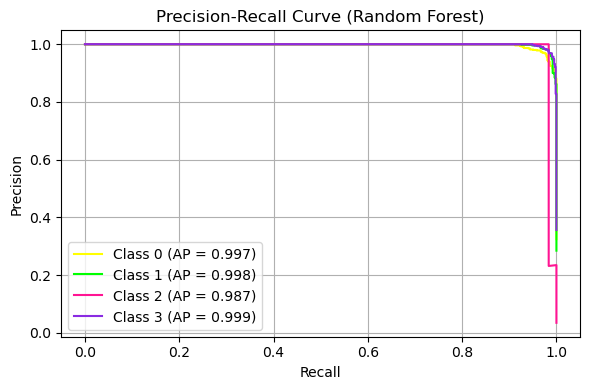

In [28]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
# Get predicted probabilities
RF_probs = RF_model.predict_proba(Xtest[final_selected_features])

# Binarize the target test data 
n_classes = RF_probs.shape[1]
Ytest_bin = label_binarize(Ytest_encoded, classes=list(range(n_classes)))
precision = {} 
recall = {} 
avg_precision = {}

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(Ytest_bin[:, i], RF_probs[:, i])
    avg_precision[i] = average_precision_score(Ytest_bin[:, i], RF_probs[:, i])

plt.figure(figsize=(6, 4))
colors = ['yellow', 'lime', 'deeppink', 'blueviolet']
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i], color=color,
             label=f'Class {i} (AP = {avg_precision[i]:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Random Forest)')
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()


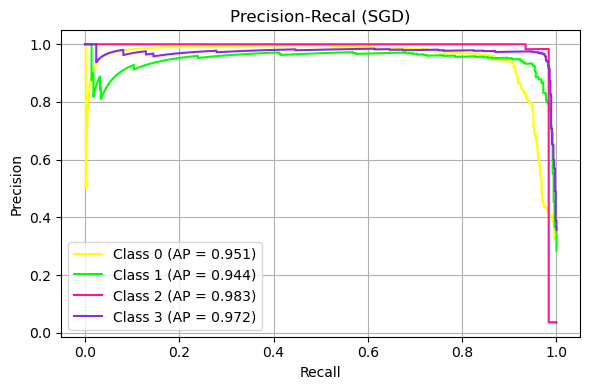

In [29]:
SGD_probs = SGD_model.predict_proba(Xtest[final_selected_features])  
n_classes = SGD_probs.shape[1]
Ytest_bin = label_binarize(Ytest_encoded, classes=list(range(n_classes)))
precision = {}
recall = {}
avg_precision = {}

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(Ytest_bin[:, i], SGD_probs[:, i])
    avg_precision[i] = average_precision_score(Ytest_bin[:, i], SGD_probs[:, i])


plt.figure(figsize=(6, 4))
colors = ['yellow', 'lime', 'deeppink', 'blueviolet']
for i, color in zip(range(n_classes), colors):
    plt.plot(recall[i], precision[i], color=color,
             label=f'Class {i} (AP = {avg_precision[i]:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recal (SGD)')
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()


In [30]:
#compare Random Forest and Logistic Regression using One-vs-Rest ROC curves: 

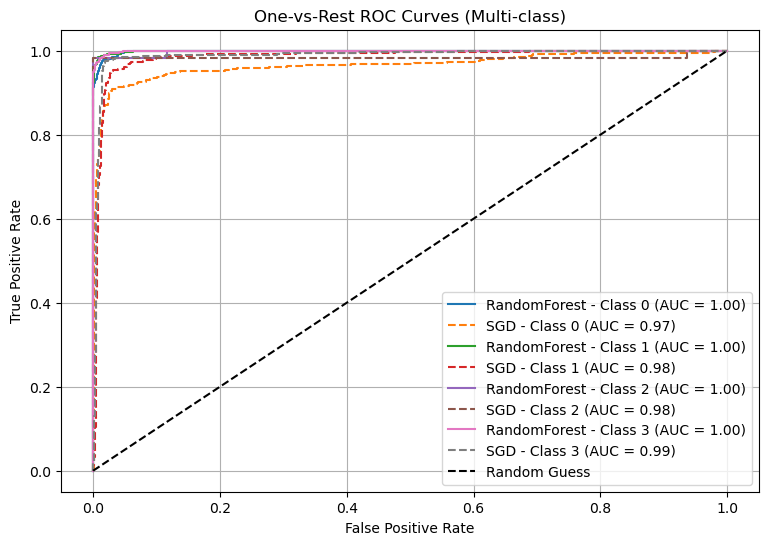

In [31]:
from sklearn.metrics import roc_curve, auc
from sklearn.multiclass import OneVsRestClassifier
# Binarize the labels for multi-class ROC
Ytest_binarized = label_binarize(Ytest_encoded, classes=[0, 1, 2, 3])
n_classes = Ytest_binarized.shape[1]
# Predict probabilities
rf_probs = RF_model.predict_proba(Xtest[final_selected_features])
sgd_probs = SGD_model.predict_proba(Xtest[final_selected_features])
# Plot ROC curve for each class
plt.figure(figsize=(9, 6))
for i in range(n_classes):
    fpr_rf, tpr_rf, _ = roc_curve(Ytest_binarized[:, i], rf_probs[:, i])
    auc_rf = auc(fpr_rf, tpr_rf)
    plt.plot(fpr_rf, tpr_rf, label=f'RandomForest - Class {i} (AUC = {auc_rf:.2f})')

    fpr_sgd, tpr_sgd, _ = roc_curve(Ytest_binarized[:, i], sgd_probs[:, i])
    auc_sgd = auc(fpr_sgd, tpr_sgd)
    plt.plot(fpr_sgd, tpr_sgd, linestyle='--', label=f'SGD - Class {i} (AUC = {auc_sgd:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate'z
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves (Multi-class)')
plt.legend()
plt.grid(True)
plt.show()

In [32]:
RFtrain_preds = RF_model.predict(Xtrain_resampled[final_selected_features])
RFtrain_acc = accuracy_score(Ytrain_resampled, RFtrain_preds)
print(f"Train Accuracy: {RFtrain_acc:.4f}")

Train Accuracy: 0.9858


In [33]:
# check the confusion_matrix:

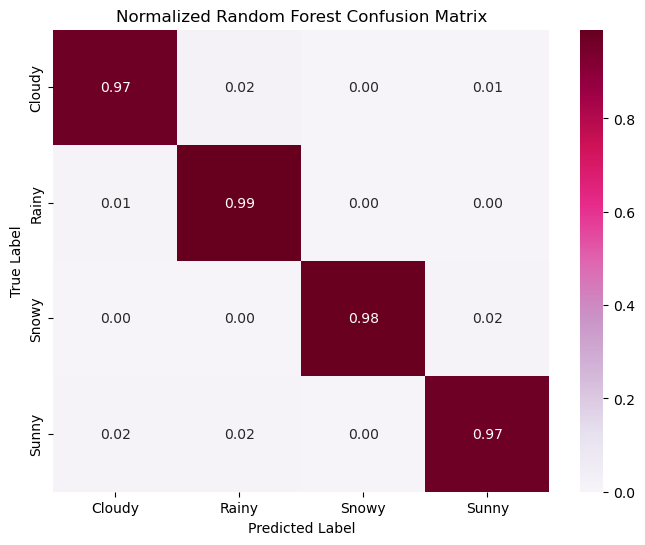

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

classes = ['Cloudy', 'Rainy', 'Snowy', 'Sunny']
cm_norm = RFCM.astype('float') / RFCM.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="PuRd", xticklabels=classes, yticklabels=classes)
plt.title("Normalized Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [36]:
# Shows which features the model relies on the most to explain which features are the most predictive.

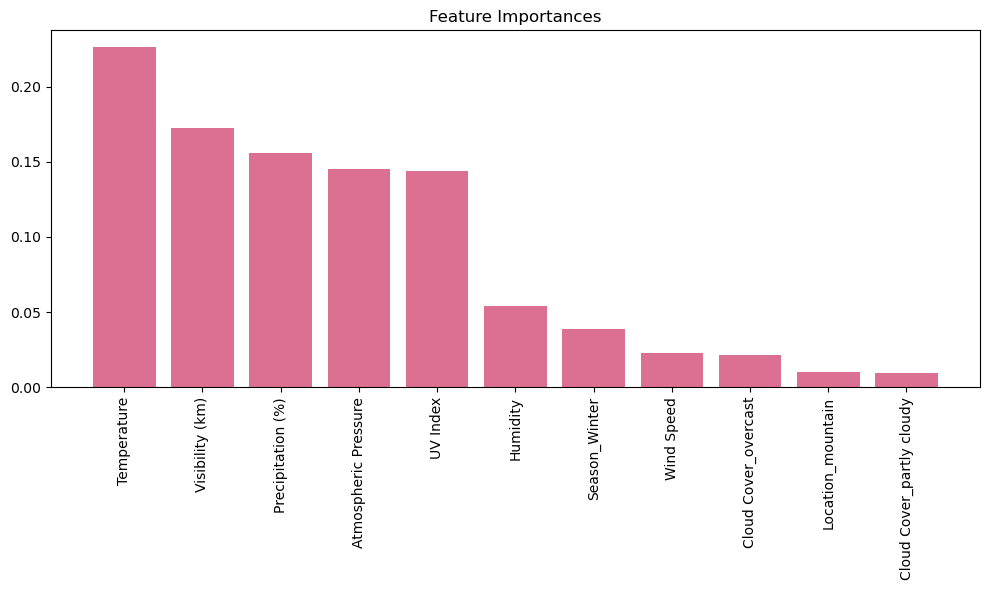

In [37]:
importances = RF_model.feature_importances_
indices = np.argsort(importances)[::-1]
features = Xtrain_resampled[final_selected_features].columns

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(len(importances)), importances[indices],color='palevioletred')
plt.xticks(range(len(importances)), [features[i] for i in indices], rotation=90)
plt.tight_layout()
plt.show()
